# NNpruning: boundary pruning for neural networks

This is the emergentSR idea (*local geometry proposes, boundaries simplify, data
decides*) ported to two networks:

1. **The moons MLP** of `pruningNN.ipynb`: 2-50-50-50-1, sigmoid, 5301 parameters.
2. **A one-layer transformer** trained from scratch on $a+b \bmod 59$: 4 heads,
   $d=64$, $d_h=16$, 256 ReLU units, 57 339 parameters.

**Selection rule.** Everything is decided on the validation split with
per-sample *paired* differences:

- **Admissible:** $\overline{c(f_m)-c(f_0)}\le 2\,\widehat{SE}$, anchored at the
  original model $f_0$.
- **Tie set:** admissible moves within $2\,\widehat{SE}$ (paired) of the best
  admissible move.
- **Tie-break:** most $k_{\rm eff}$ removed first, then the earliest layer.

The test split is only reported, never used for a decision.

**Limits are stored by their exact representative**, never as huge numbers:
saturations and fan-in→0 become constants folded into the next bias, a layer-0
weight→±∞ becomes a Heaviside unit, and softmax limits become uniform or fixed
patterns. See `README.md` for the move table and for what is classical versus new.

Set `RECOMPUTE = True` to rerun from scratch. On a laptop CPU this takes about
10 min per MLP seed and about 1 h for the transformer. Otherwise the cached
results in `results/` are loaded.

In [1]:
import os, sys, json
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
from nnprune import experiments as E

RECOMPUTE    = False          # True: retrain and re-prune everything
RUN_SPECTRUM = True           # full 5301x5301 expected-GGN spectrum of the MLP (~1-2 min)
MLP_SEEDS    = (123, 7, 42)
TF_SEEDS     = (0,)
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")

In [2]:
# Plot styling: fixed categorical order, thin marks, recessive axes, one y-axis per chart.
PAL  = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2.0,
    "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9.5,
})
BASES = ["magnitude", "obd", "wanda", "random", "mean_ablation"]

FDIST = ["fdist_one_shot", "fdist_iterative", "fdist_global", "fdist_exact"]

def frontier(paths, bls, main, metric, ylabel, title, criterion="loss", logy=False, ax=None, bases=None):
    # one curve per method; a ring marks where each method stops under the anchored test
    ax = ax or plt.subplots(figsize=(7.2, 4.0))[1]
    series = [(main, paths[paths.method == main])] + [(b, bls[bls.method == b]) for b in (bases or BASES)]
    for k, (name, df) in enumerate(series):
        if df.empty:
            continue
        col = PAL[k]
        x = 100 * df["frac_removed"].values
        ax.plot(x, df[metric].values, color=col, lw=2.0 if k == 0 else 1.4, label=name)
        stop = df.iloc[-1] if k == 0 else df[df[f"within_tolerance_{criterion}"]].iloc[-1]
        ax.plot(100 * stop["frac_removed"], stop[metric], "o", ms=8, mfc="#fcfcfb", mec=col, mew=2)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("% of k_eff removed"); ax.set_ylabel(ylabel); ax.set_title(title, loc="left")
    ax.legend(loc="best")
    return ax

def composition(paths, methods, title):
    # share of the removed k_eff contributed by each move kind (seed-averaged)
    kinds = ["zero", "unit_merge", "unit_mean", "unit_sat", "unit_step",
             "head_off", "head_mean", "attn_uniform", "attn_fixed", "qk_rank", "ov_rank"]
    rows = []
    for m in methods:
        d = paths[(paths.method == m) & (paths.step > 0)]
        tot = d.groupby("kind")["dk"].sum()
        rows.append((tot / tot.sum()).reindex(kinds).fillna(0).rename(m))
    T = pd.DataFrame(rows)
    T = T.loc[:, T.sum(axis=0) > 0]
    fig, ax = plt.subplots(figsize=(7.2, 0.45 * len(methods) + 1.2))
    left = np.zeros(len(T))
    for k, kind in enumerate(T.columns):
        ax.barh(range(len(T)), T[kind], left=left, color=PAL[k % len(PAL)], edgecolor="#fcfcfb",
                linewidth=2, label=kind, height=0.62)
        left += T[kind].values
    ax.set_yticks(range(len(T))); ax.set_yticklabels(T.index); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xlabel("share of removed k_eff"); ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.32))
    plt.tight_layout()
    return T

def seed_table(summary):
    g = summary.groupby("method")
    T = pd.DataFrame({
        "% k_eff removed": 100 * g["frac_removed"].mean(),
        "sd": 100 * g["frac_removed"].std(),
        "k_eff left": g["k_eff"].mean(),
        "test loss": g["test_loss"].mean(),
        "test acc": g["test_acc"].mean(),
        "steps": g["steps"].mean(),
    })
    return T.sort_values("% k_eff removed", ascending=False)

---
## 1. Moons MLP

These are the same data generator, architecture and training recipe as
`pruningNN.ipynb`. The split is now train / validation / test (60/20/20), and
the scaler is fit on train only. Three seeds are used; each seed changes both
the data draw and the initialisation.

In [3]:
mlp = E.run_mlp("results/mlp", seeds=MLP_SEEDS, recompute=RECOMPUTE)
mlp["base"]

,seed,k_eff,train_loss,train_acc,val_loss,val_acc,test_loss,test_acc
0,123,5301,0.151,0.944,0.166,0.942,0.1181,0.954
1,7,5301,0.1352,0.9427,0.1033,0.956,0.1263,0.938
2,42,5301,0.1347,0.9453,0.1388,0.944,0.1522,0.932


**Summary at each method's own stopping point, mean over seeds.** For the
boundary variants this is where the path stops. For the one-shot baselines it is
the last sparsity before the anchored 2σ test first fails. All rows are in
k_eff units.

In [4]:
seed_table(mlp["summary"])

,% k_eff removed,sd,k_eff left,test loss,test acc,steps
method,,,,,,
boundary [k_eff],99.67,0.08713,17.67,0.1671,0.9367,177.7
classical moves [k_eff>layer],99.6,0.1237,21,0.1485,0.9393,146.7
boundary [layer],99.6,0.05763,21.33,0.1525,0.9467,242.7
boundary [no tie-break],99.58,0.1544,22,0.1549,0.938,282.3
boundary [k_eff>layer],99.3,0.1969,37,0.1581,0.9407,166.7
sat+step moves [k_eff>layer],41.25,14.06,3114,0.1551,0.944,100
weights only [k_eff>layer],36.48,7.862,3367,0.1569,0.942,97.67
mean_ablation,15.42,9.932,4484,0.1434,0.942,NaN
wanda,7.772,3.365,4889,0.1514,0.9373,NaN


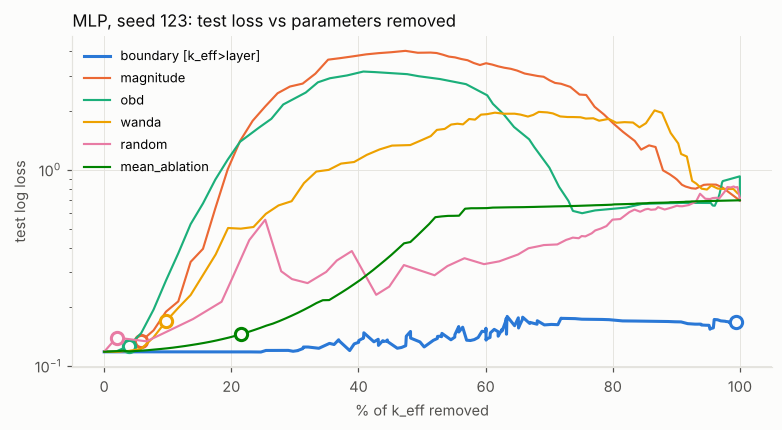

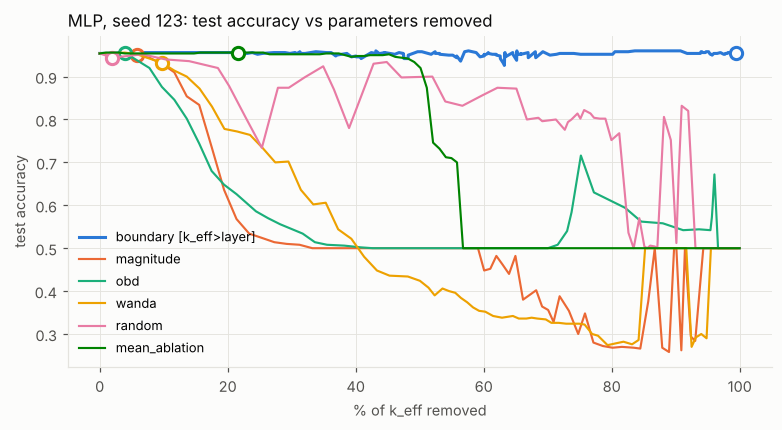

In [5]:
P, B = mlp["paths"], mlp["baselines"]
s = MLP_SEEDS[0]
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer]", "test_loss", "test log loss",
         f"MLP, seed {s}: test loss vs parameters removed", logy=True)
plt.tight_layout(); plt.show()
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer]", "test_acc", "test accuracy",
         f"MLP, seed {s}: test accuracy vs parameters removed")
plt.tight_layout(); plt.show()

**Which moves did the work.** Each bar is the share of removed $k_{\rm eff}$
contributed by each move kind, pooled over seeds. The bottom three bars are
move-set ablations under the same rule:

- *weights only*: no structural moves.
- *classical moves*: mean replacement plus merging.
- *sat+step moves*: only the saturation and Heaviside boundaries.

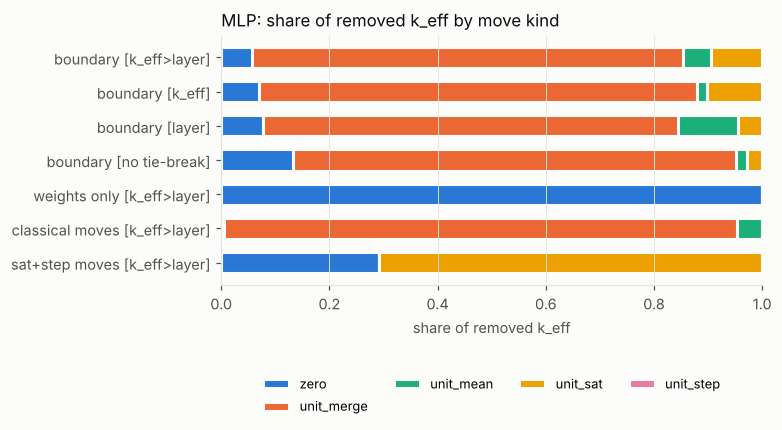

In [6]:
variants = list(E.MLP_VARIANTS)
composition(P, variants, "MLP: share of removed k_eff by move kind"); plt.show()

**Against Berman et al. (2026).** Their four Fisher-distance schemes are run
with their own Fisher code (vendored verbatim from `edhirst/Fdist_Pruning`) and
their protocol: model Fisher on a 500-point training subset, $K=3$, global
unstructured pruning, no retraining. Evaluation is identical to the other
baselines: the anchored 2σ test on validation, and $k_{\rm eff}$ after cascades.
`tests/test_fdist.py` checks that our runs zero exactly the entries their
pruner classes zero.

,% k_eff removed,sd,k_eff left,test loss,test acc,steps
method,,,,,,
boundary [k_eff>layer],99.3,0.1969,37,0.1581,0.9407,166.7
fdist_global,6.653,1.915,4948,0.1415,0.938,NaN
magnitude,6.477,1.122,4958,0.1417,0.9393,NaN
fdist_iterative,5.112,2.696,5030,0.1392,0.938,NaN
fdist_exact,4.88,2.515,5042,0.1391,0.938,NaN
obd,4.741,3.31,5050,0.1362,0.9447,NaN
fdist_one_shot,4.232,2.357,5077,0.1343,0.9413,NaN


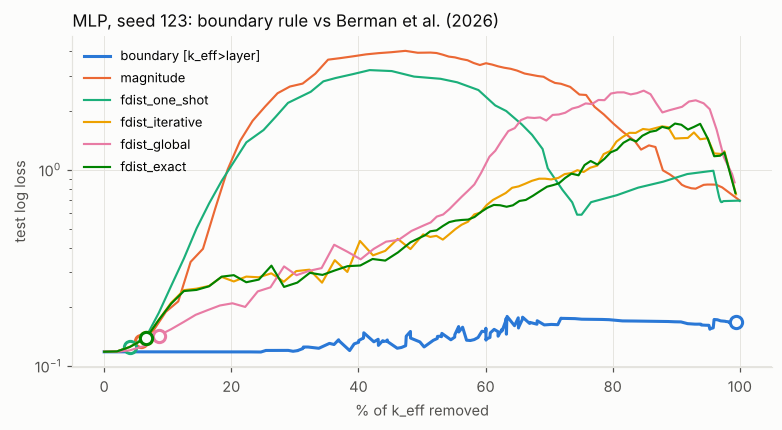

In [7]:
fdm = E.run_fdist("mlp", recompute=RECOMPUTE)
T = pd.concat([mlp["summary"][mlp["summary"].method.isin(["boundary [k_eff>layer]", "magnitude", "obd"])],
               fdm["fdist_summary_loss"]])
display(seed_table(T))
P, B = mlp["paths"], pd.concat([mlp["baselines"], fdm["fdist_baselines"]])
s = MLP_SEEDS[0]
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer]", "test_loss", "test log loss",
         f"MLP, seed {s}: boundary rule vs Berman et al. (2026)", logy=True, bases=["magnitude"] + FDIST)
plt.tight_layout(); plt.show()

**Identifiability of the trained MLP.** This is the full $5301\times5301$
expected GGN on a fresh draw of $n=8000>p$ points, so a null space cannot be a
sample-size artefact. The gap rule from `criteria_bench` is applied with a
numerical noise floor (see the note in section 3).

under_determined | null_dim 0 | small eigenvalues present (min 3.6e-15 of lambda_max) but the widest gap is only 0.9 decades < min_decades=3.0
null_dim without the noise floor: 2577
min_decades sweep: [(1.0, 0), (2.0, 0), (3.0, 0), (4.0, 0), (6.0, 0), (8.0, 0)]
eigenvalues above the noise floor: 93 of 5301


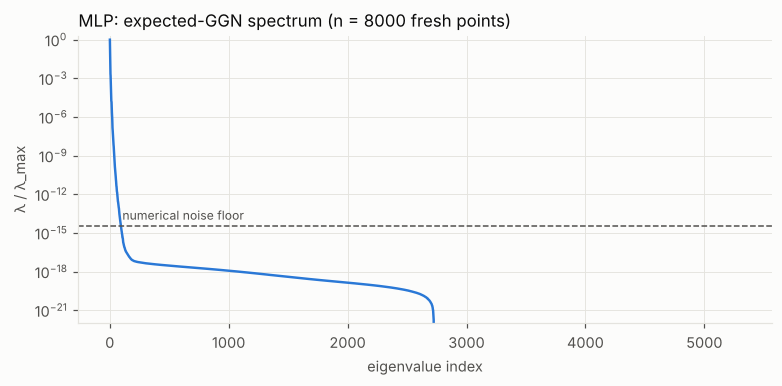

In [8]:
if RUN_SPECTRUM:
    sp = E.mlp_spectrum("results/mlp", seed=MLP_SEEDS[0], recompute=RECOMPUTE)
    print(sp["regime"], "| null_dim", sp["null_dim"], "|", sp["reason"])
    print("null_dim without the noise floor:", sp["null_dim_without_floor"])
    print("min_decades sweep:", [(r["min_decades"], r["null_dim"]) for r in sp["sweep"]])
    ev = np.array(sp["eigenvalues"]); mu = np.clip(ev / ev[0], 1e-300, None)
    print(f"eigenvalues above the noise floor: {(mu > sp['noise_floor']).sum()} of {len(mu)}")
    fig, ax = plt.subplots(figsize=(7.2, 3.6))
    ax.semilogy(np.arange(1, len(mu) + 1), mu, color=PAL[0], lw=1.6)
    ax.axhline(sp["noise_floor"], color=INK2, lw=1, ls="--")
    ax.text(len(mu) * 0.02, sp["noise_floor"] * 3, "numerical noise floor", color=INK2, fontsize=8)
    ax.set_ylim(max(mu.min(), 1e-22), 2); ax.set_xlabel("eigenvalue index")
    ax.set_ylabel("λ / λ_max"); ax.set_title("MLP: expected-GGN spectrum (n = 8000 fresh points)", loc="left")
    plt.tight_layout(); plt.show()

---
## 2. One-layer transformer on $a+b \bmod 59$

The model is trained from scratch with AdamW (weight decay 1, full batch, 3000
steps) on 50% of the pairs. Validation and test are 25% each. It generalises
fully by step about 1000.

### 2a. Where are the structural nulls?

Every head's QK and OV block and a few MLP units are classified by the gap
rule, using the expected Fisher over **all** $59^2$ inputs (the whole
population). Two columns give the null dimension independently of the Fisher:

- **`predicted_null`** comes from ranks of data subspaces. For QK it is
  $2dd_h-r_K$, where $r_K$ is the rank of the key differences.
- **`symmetry_null`** is what the symmetry alone gives:
  - QK: $2dd_h-d$, because the query token '=' is constant.
  - OV: $d_h^2$, the GL($d_h$) gauge.
  - A ReLU unit: 1, the rescaling gauge.

In [9]:
tf = E.run_transformer("results/transformer", seeds=TF_SEEDS, recompute=RECOMPUTE)
display(tf["base"])
tf["gauge"]

,seed,k_eff,train_loss,train_acc,val_loss,val_acc,test_loss,test_acc
0,0,57339,0.0005178,1,0.0007628,1,0.0008369,1


,block,p,regime,null_dim,predicted_null,symmetry_null,plateau_decades,n_at_noise_floor,null_dim_without_floor,null_dims_over_min_decades,seed
0,head0.QK,2048,structural,1988,1988,1984,4.407,1988,1988,"[1988, 1988, 1988, 1988, 0, 0]",0
1,head0.OV,2048,under_determined,0,320,256,2.051,569,170,"[0, 0, 0, 0, 0, 0]",0
2,head1.QK,2048,structural,1988,1988,1984,4.58,1988,1988,"[1988, 1988, 1988, 1988, 0, 0]",0
3,head1.OV,2048,under_determined,0,320,256,2.761,553,168,"[0, 0, 0, 0, 0, 0]",0
4,head2.QK,2048,structural,1988,1988,1984,4.874,1988,1988,"[1988, 1988, 1988, 1988, 0, 0]",0
5,head2.OV,2048,under_determined,0,320,256,2.008,601,170,"[0, 0, 0, 0, 0, 0]",0
6,head3.QK,2048,structural,1988,1988,1984,3.629,1988,1988,"[1988, 1988, 1988, 0, 0, 0]",0
7,head3.OV,2048,under_determined,0,320,256,2.361,562,170,"[0, 0, 0, 0, 0, 0]",0
8,unit0 (active 0.58),129,under_determined,0,NaN,1,2.279,10,4,"[0, 0, 0, 0, 0, 0]",0
9,unit1 (active 0.63),129,under_determined,0,NaN,1,2.303,12,2,"[0, 0, 0, 0, 0, 0]",0


### 2b. Pruning

The transformer is trained to a log loss of about $10^{-4}$ on a deterministic
task, so the two criteria behave differently:

- **`loss`**: the paired 2σ test on per-sample log loss.
- **`error`**: the same test on per-sample 0/1 error.

Weight moves are proposed in chunks of 64 (`weight_chunk`).

In [10]:
display(seed_table(tf["summary_loss"]).rename_axis("criterion = loss"))
seed_table(tf["summary_error"]).rename_axis("criterion = error")

,% k_eff removed,sd,k_eff left,test loss,test acc,steps
criterion = loss,,,,,,
boundary [k_eff>layer] loss,46.45,NaN,3.07e+04,0.0009591,1,212
magnitude,3.973,NaN,5.506e+04,0.0008443,1,NaN
wanda,1.986,NaN,5.62e+04,0.0008392,1,NaN
mean_ablation,0,NaN,5.734e+04,0.0008369,1,NaN
obd,0,NaN,5.734e+04,0.0008369,1,NaN
random,0,NaN,5.734e+04,0.0008369,1,NaN


,% k_eff removed,sd,k_eff left,test loss,test acc,steps
criterion = error,,,,,,
boundary [k_eff>layer] error,81.3,NaN,1.072e+04,0.2873,0.9885,385
boundary [layer] error,73.84,NaN,1.5e+04,0.8827,0.9793,421
weights only [k_eff>layer] error,38.22,NaN,3.542e+04,1.381,0.9759,341
magnitude,27.82,NaN,4.139e+04,0.02206,0.9977,NaN
mean_ablation,26.77,NaN,4.199e+04,0.04148,0.9966,NaN
wanda,15.89,NaN,4.822e+04,0.02036,0.9989,NaN
random,1.986,NaN,5.62e+04,0.02876,0.9989,NaN
obd,0,NaN,5.734e+04,0.0008369,1,NaN


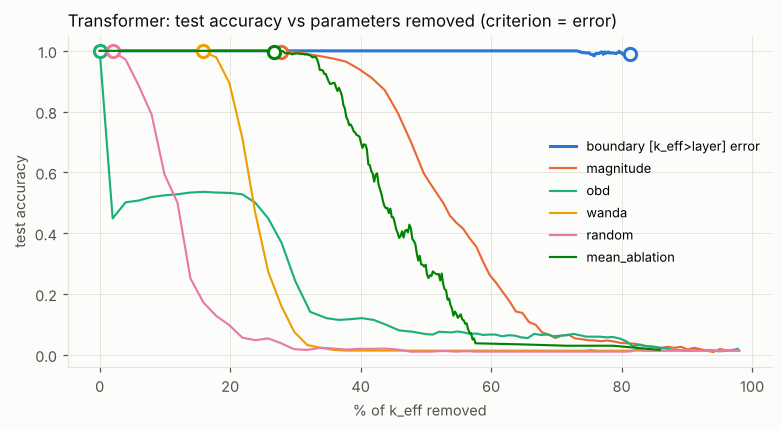

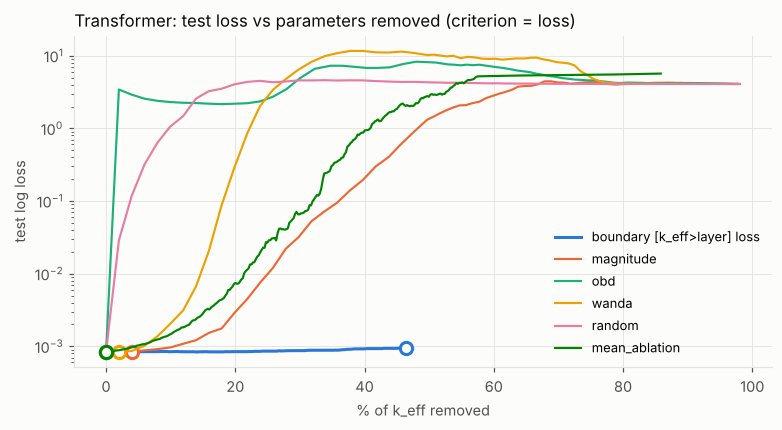

In [11]:
P, B = tf["paths"], tf["baselines"]
s = TF_SEEDS[0]
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer] error", "test_acc", "test accuracy",
         "Transformer: test accuracy vs parameters removed (criterion = error)", criterion="error")
plt.tight_layout(); plt.show()
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer] loss", "test_loss", "test log loss",
         "Transformer: test loss vs parameters removed (criterion = loss)", criterion="loss", logy=True)
plt.tight_layout(); plt.show()

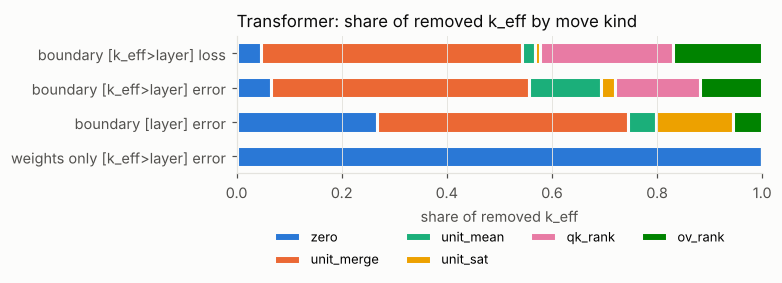

In [12]:
composition(P, list(E.TF_VARIANTS), "Transformer: share of removed k_eff by move kind"); plt.show()

**Against Berman et al. (2026) on the transformer.** The schemes are one-shot,
iterative and global-path. The exact scheme needs about $57{,}000\times K$
forward-mode probes per sparsity step, which is too slow on a laptop CPU, so it
is not run here. Following their transformer policy, the positional embedding
is not pruned.

,% k_eff removed,sd,k_eff left,test loss,test acc,steps
criterion = loss,,,,,,
boundary [k_eff>layer] loss,46.45,NaN,3.07e+04,0.0009591,1,212
fdist_global,5.999,NaN,5.39e+04,0.0008806,1,NaN
fdist_iterative,5.999,NaN,5.39e+04,0.000861,1,NaN
fdist_one_shot,5.999,NaN,5.39e+04,0.0008723,1,NaN
magnitude,3.973,NaN,5.506e+04,0.0008443,1,NaN
obd,0,NaN,5.734e+04,0.0008369,1,NaN


,% k_eff removed,sd,k_eff left,test loss,test acc,steps
criterion = error,,,,,,
boundary [k_eff>layer] error,81.3,NaN,1.072e+04,0.2873,0.9885,385
fdist_iterative,34.01,NaN,3.784e+04,0.03117,1,NaN
magnitude,27.82,NaN,4.139e+04,0.02206,0.9977,NaN
fdist_global,26.02,NaN,4.242e+04,0.05505,0.9966,NaN
fdist_one_shot,10,NaN,5.16e+04,0.006094,1,NaN
obd,0,NaN,5.734e+04,0.0008369,1,NaN


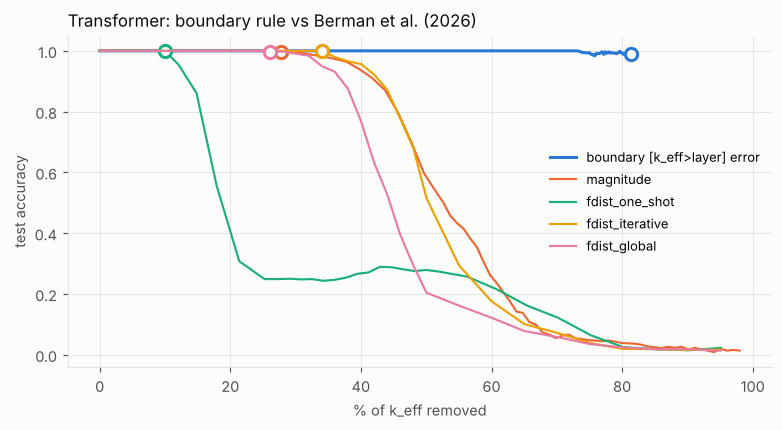

In [13]:
fdt = E.run_fdist("transformer", recompute=RECOMPUTE)
for crit in ("loss", "error"):
    main = f"boundary [k_eff>layer] {crit}"
    S = tf[f"summary_{crit}"]
    T = pd.concat([S[S.method.isin([main, "magnitude", "obd"])], fdt[f"fdist_summary_{crit}"]])
    display(seed_table(T).rename_axis(f"criterion = {crit}"))
P, B = tf["paths"], pd.concat([tf["baselines"], fdt["fdist_baselines"]])
s = TF_SEEDS[0]
frontier(P[P.seed == s], B[B.seed == s], "boundary [k_eff>layer] error", "test_acc", "test accuracy",
         "Transformer: boundary rule vs Berman et al. (2026)", criterion="error",
         bases=["magnitude"] + FDIST[:3])
plt.tight_layout(); plt.show()

---
## 3. Findings on the cached run (MLP seeds 123/7/42, transformer seed 0)

**MLP**

- **Main result.** The boundary rule removes $99.3\% \pm 0.2$ of $k_{\rm eff}$,
  leaving 30–49 parameters. Test accuracy is unchanged at 0.941 (base 0.941).
  Test loss rises from 0.132 to 0.158.
- **Baselines.** Under the same anchored test, the one-shot baselines stop at
  2–8%. Mean-ablation stops at 15%.
- **Which moves matter.** Most of the work is done by `unit_merge`. The trained
  network is full of near-duplicate neurons, with |corr| > 0.999. That is the
  Fukumizu–Amari singularity approached in practice. The ablations show the
  balance:
  - Classical moves alone (mean + merge) reach 99.6%.
  - The saturation/Heaviside boundaries alone reach 41%.
  - Weights alone under the same rule reach 36%. Compare that with 6.5% for
    one-shot magnitude: the selection rule itself is worth a lot.
- **Tie-break.** The four variants all land in 99.3–99.7%. On this easy problem
  the tie-break does not matter.
- **Berman et al. (2026), run with their own Fisher code.** Their iterative
  and exact schemes clearly beat magnitude pruning along the curve. At 30% of
  $k_{\rm eff}$ removed, the test loss (mean over seeds) is:

  | method | test loss at 30% |
  |---|---|
  | `fdist_exact` | 0.30 |
  | `fdist_iterative` | 0.32 |
  | magnitude | 1.69 |
  | one-shot `fdist` | 1.56 |
  | boundary rule | 0.132 (flat) |

  Under the anchored 2σ test every member of their family stops at 4–7%,
  like the other one-shot unstructured baselines.
- **Spectrum.** Only 93 of the 5301 eigenvalues of the expected GGN sit
  above the float64 noise floor, and they decay smoothly into it. The verdict is
  therefore **under-determined**: there is no gap above the noise floor. The duplicates are *near* the singularity, not on it.
  Removing them is a tolerance decision taken by the 2σ rule, not a zero-cost
  repair.

**Transformer**

- **QK blocks are structurally singular.** All four heads give
  `null_dim = 1988/2048`, which equals the independent prediction
  $2dd_h-r_K$ with $r_K=60$ (60 = number of token embeddings). The plateau is
  3.6–4.9 decades. The `qk_rank` moves (activation-weighted SVD) carry out
  exactly this repair at zero loss.
- **OV blocks and MLP units are under-determined.** Their gauge nulls are buried
  in a sloppy tail that reaches the noise floor.
- **`criterion = loss`.** The path removes 46.5% of $k_{\rm eff}$ with 0 test
  errors, and test loss barely moves ($8.4\cdot10^{-4}\to9.6\cdot10^{-4}$).
  The one-shot baselines pass the same test only up to 0–4%.
- **`criterion = error`.** The path removes 81.3%, with test accuracy 0.9885.
  Test accuracy at matched sparsity:

  | method | 10% | 20% | 30% | 40% | 50% | 70% |
  |---|---|---|---|---|---|---|
  | boundary | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
  | magnitude | | | 0.997 | 0.94 | 0.60 | |
  | mean-ablation | | | 0.99 | 0.72 | | |
  | Wanda | | 0.89 | | | | |
  | OBD | 0.53 | | | | | |

  OBD is weak here because at a log loss of about $10^{-4}$ the Fisher and the
  gradient are tiny and noisy.
- **Berman et al. (2026) on the transformer.**
  - `fdist_iterative` is the best of their family. Its test accuracy is 1.000
    up to 30% removed, then 0.97 at 40% and 0.68 at 50% (magnitude: 0.94 and
    0.60).
  - Under the error criterion it stays within tolerance up to 34%; under the
    loss criterion up to 6%.
  - At matched sparsity the boundary rule keeps 1.000 up to 70%.
- **Layer tie-break.** Preferring earlier layers is clearly worse on the
  transformer. It favours embedding chunks: test loss is already 0.10 at 10%
  sparsity, against $8\cdot10^{-4}$ with $k_{\rm eff}$ first. It stops at 73.8%.

## 4. Notes

- **Noise floor in the gap rule.** On a block whose spectrum decays smoothly into
  rounding noise, `criteria_bench.spectrum.classify_spectrum` as written finds a
  ~290-decade gap. That gap sits between the small positive rounding errors and
  the small negative ones, which are clipped to 0. The returned `null_dim` is
  then the number of negative rounding errors (`null_dim_without_floor` in the
  gauge table: 168–170 for OV).
  `classify_spectrum(..., noise_floor="auto")` raises everything below the
  empirical floor (the size of the most negative eigenvalue, but at least
  16 eps) before reading the gaps. With the floor, such spectra are called
  under-determined, and the QK verdicts are unchanged. The original code is
  unchanged.
- **Resolution of the paired 2σ test.** If a move damages only $k$ of $n$
  validation points, then mean/SE $\approx\sqrt{k}$, so the anchored test
  admits damage concentrated on $k\lesssim4$ points, however large it is.
  Under `criterion = error`, all three transformer paths stop at exactly
  **3** extra validation errors. On the untouched test set they make **10, 18
  and 21** errors: hundreds of greedy selections on one validation set overfit
  it. The loss criterion is much better behaved (0 test errors), because it
  sees confidence and not only the argmax.
- **Composition plots** credit each step's $\Delta k_{\rm eff}$, including
  cascades, to the move that triggered it.